# Statistics & Visual EDA

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the saved clean dataset
file_path = r"D:\Project\Banking_Customer_churn&_Retention\Data\processed\bank_churn_clean.csv"
bank_clean = pd.read_csv(file_path)

# Define the aggregation helper function
def churn_by_group(df, group_col):
    summary = df.groupby(group_col).agg(
        total_customers=('exited', 'count'),
        churned_customers=('exited', 'sum'),
        churn_rate_pct=('exited', lambda x: round(x.mean() * 100, 2))
    ).reset_index()
    return summary

In [2]:
sns.set_theme(style = "whitegrid")

In [3]:
 # 1. Churn by Geography

In [4]:
geo_churn = churn_by_group(bank_clean, 'geography')
print("--- Churn by Country ---")
display(geo_churn)

--- Churn by Country ---


,geography,total_customers,churned_customers,churn_rate_pct
0,France,5014,810,16.15
1,Germany,2509,814,32.44
2,Spain,2477,413,16.67


In [5]:
# 2. Churn by Active Status

In [6]:
active_churn = churn_by_group(bank_clean, 'is_active')
print("\n--- Churn by Active Status (0 = Inactive, 1 = Active) ---")
display(active_churn)


--- Churn by Active Status (0 = Inactive, 1 = Active) ---


,is_active,total_customers,churned_customers,churn_rate_pct
0,0,4849,1302,26.85
1,1,5151,735,14.27


In [7]:
# 3. Churn by Number of Products

In [8]:
product_churn = churn_by_group(bank_clean, 'num_of_products')
print("\n--- Churn by Number of Products ---")
display(product_churn)


--- Churn by Number of Products ---


,num_of_products,total_customers,churned_customers,churn_rate_pct
0,1,5084,1409,27.71
1,2,4590,348,7.58
2,3,266,220,82.71
3,4,60,60,100.00


In [9]:
# 1. Churn by Gender
gender_churn = churn_by_group(bank_clean, 'gender')
print("--- Churn by Gender ---")
display(gender_churn)

# 2. Binning Age into demographic bands
bank_clean['age_group'] = pd.cut(
    bank_clean['age'],
    bins=[17, 30, 40, 50, 60, 100],
    labels=['18-30', '31-40', '41-50', '51-60', '60+']
)
age_churn = churn_by_group(bank_clean, 'age_group')
print("\n--- Churn by Age Group ---")
display(age_churn)

# 3. Binning Balance (Zero Balance vs Funded Accounts)
bank_clean['balance_category'] = pd.cut(
    bank_clean['balance'],
    bins=[-1, 0, 50000, 100000, 150000, 300000],
    labels=['Zero Balance', 'Under 50k', '50k-100k', '100k-150k', '150k+']
)
balance_churn = churn_by_group(bank_clean, 'balance_category')
print("\n--- Churn by Balance Category ---")
display(balance_churn)

--- Churn by Gender ---


,gender,total_customers,churned_customers,churn_rate_pct
0,Female,4543,1139,25.07
1,Male,5457,898,16.46



--- Churn by Age Group ---


,age_group,total_customers,churned_customers,churn_rate_pct
0,18-30,1968,148,7.52
1,31-40,4451,538,12.09
2,41-50,2320,788,33.97
3,51-60,797,448,56.21
4,60+,464,115,24.78



--- Churn by Balance Category ---


,balance_category,total_customers,churned_customers,churn_rate_pct
0,Zero Balance,3617,500,13.82
1,Under 50k,75,26,34.67
2,50k-100k,1509,300,19.88
3,100k-150k,3830,987,25.77
4,150k+,969,224,23.12


C:\Users\USER\AppData\Local\Temp\ipykernel_19028\728623227.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\USER\AppData\Local\Temp\ipykernel_19028\728623227.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\USER\AppData\Local\Temp\ipykernel_19028\728623227.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\USER\AppData\Local\Temp\ipykernel_19028\728623227.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and s

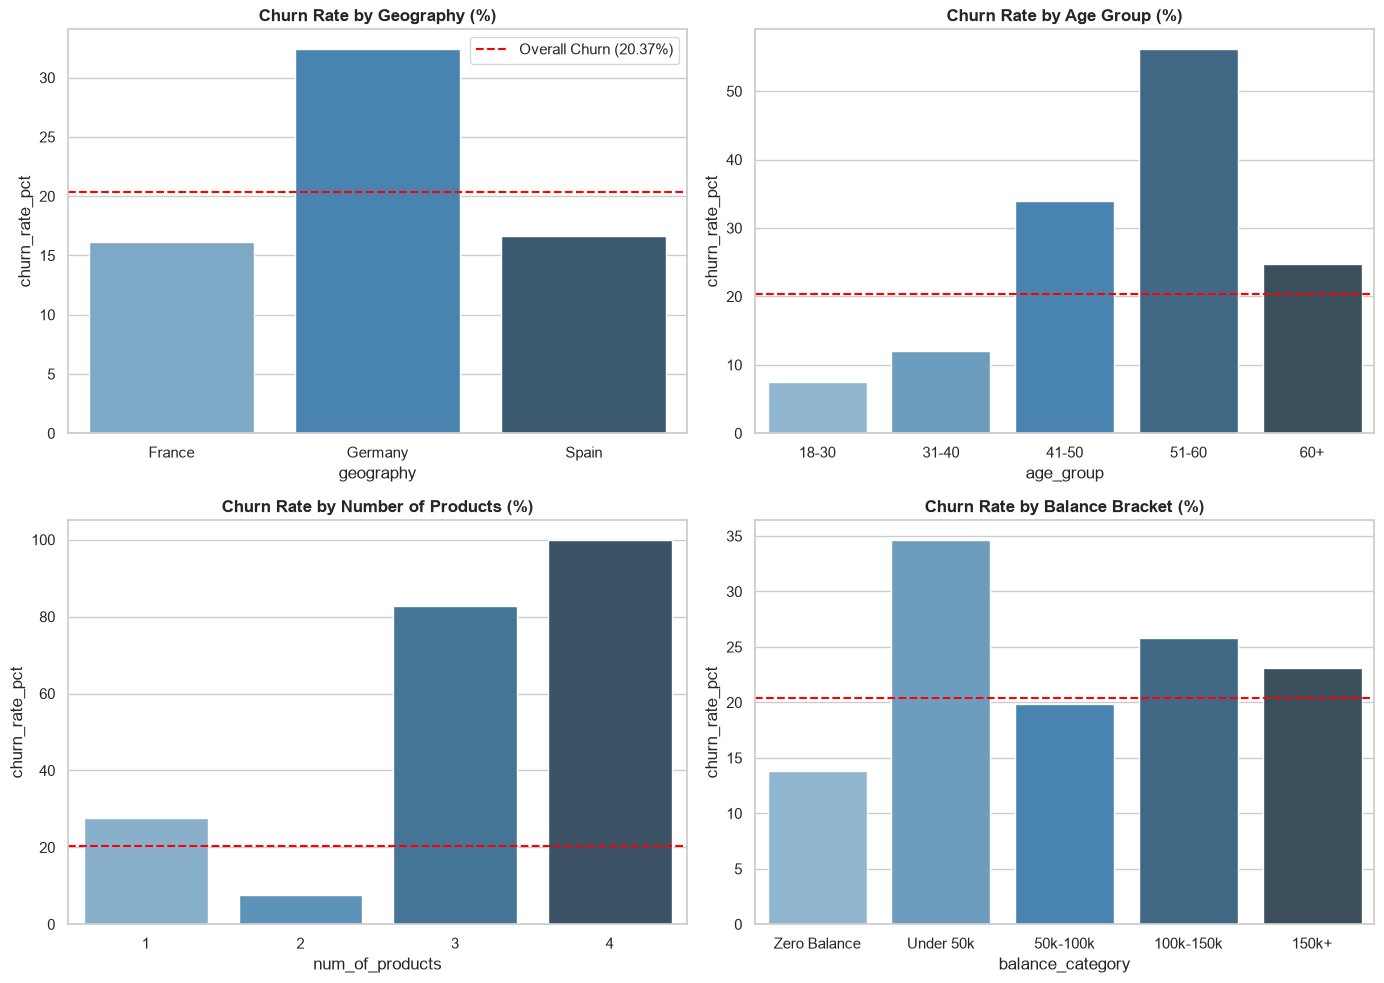

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Geography Churn Rate
sns.barplot(
    data=geo_churn, x='geography', y='churn_rate_pct',
    palette='Blues_d', ax=axes[0, 0]
)
axes[0, 0].set_title("Churn Rate by Geography (%)", fontsize=12, fontweight='bold')
axes[0, 0].axhline(20.37, color='red', linestyle='--', label='Overall Churn (20.37%)')
axes[0, 0].legend()

# Plot 2: Age Group Churn Rate
sns.barplot(
    data=age_churn, x='age_group', y='churn_rate_pct',
    palette='Blues_d', ax=axes[0, 1]
)
axes[0, 1].set_title("Churn Rate by Age Group (%)", fontsize=12, fontweight='bold')
axes[0, 1].axhline(20.37, color='red', linestyle='--', label='Overall Churn (20.37%)')

# Plot 3: Number of Products Churn Rate
sns.barplot(
    data=product_churn, x='num_of_products', y='churn_rate_pct',
    palette='Blues_d', ax=axes[1, 0]
)
axes[1, 0].set_title("Churn Rate by Number of Products (%)", fontsize=12, fontweight='bold')
axes[1, 0].axhline(20.37, color='red', linestyle='--', label='Overall Churn (20.37%)')

# Plot 4: Balance Category Churn Rate
sns.barplot(
    data=balance_churn, x='balance_category', y='churn_rate_pct',
    palette='Blues_d', ax=axes[1, 1]
)
axes[1, 1].set_title("Churn Rate by Balance Bracket (%)", fontsize=12, fontweight='bold')
axes[1, 1].axhline(20.37, color='red', linestyle='--', label='Overall Churn (20.37%)')

plt.tight_layout()
plt.show()

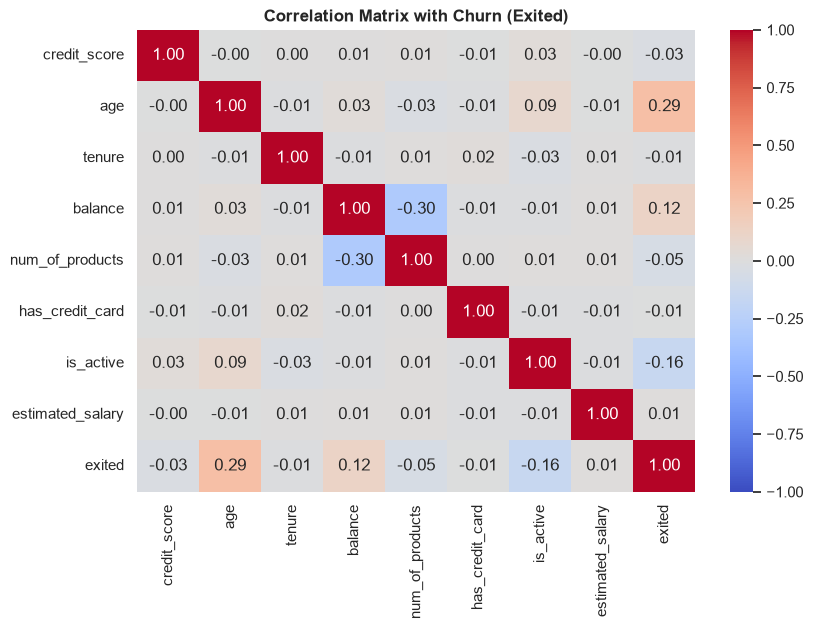

Correlation with Exited:
exited              1.000000
age                 0.285323
balance             0.118533
estimated_salary    0.012097
has_credit_card    -0.007138
tenure             -0.014001
credit_score       -0.027094
num_of_products    -0.047820
is_active          -0.156128
Name: exited, dtype: float64


In [11]:
# Select numeric columns for correlation
numeric_cols = [
    'credit_score', 'age', 'tenure', 'balance', 
    'num_of_products', 'has_credit_card', 'is_active', 
    'estimated_salary', 'exited'
]

corr_matrix = bank_clean[numeric_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix with Churn (Exited)", fontsize=12, fontweight='bold')
plt.show()

print("Correlation with Exited:")
print(corr_matrix['exited'].sort_values(ascending=False))

In [12]:
# Exporting final clean dataset
export_path = r"D:\Project\Banking_Customer_churn&_Retention\Data\processed\bank_churn_clean.csv"
bank_clean.to_csv(export_path, index=False)
